In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score,f1_score,roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import xgboost as xgb
import joblib
from pathlib import Path

MasterDataFrame = pd.read_csv('FeatureEngineeredDataFrame.csv')
DropColumn = list(MasterDataFrame.columns)
MasterDataFrame = MasterDataFrame.drop(columns=DropColumn[0])

parent_dir = Path().resolve().parent
print(parent_dir)

C:\Users\arnav\InequalitySpikesWarningSys


In [3]:
IsoToCountryDataFrame = pd.read_excel('CLASS_2025_10_07.xlsx')
ColumnsToKeepIso = ['Economy','Code']
DropColumnIso = [i for i in IsoToCountryDataFrame.columns if i not in ColumnsToKeepIso]
IsoToCountryDataFrame = IsoToCountryDataFrame.drop(columns=DropColumnIso)
IsoToCountryDataFrame = IsoToCountryDataFrame.rename(columns={'Economy':'country','Code':'countryiso3code'})
#this is to add column country names

In [4]:
NumberOfSpikesandNonSpikes = list(MasterDataFrame['GiniSpikeWithinThreeYears'].value_counts())
RatioBetweenSpikesAndNonSpikes = NumberOfSpikesandNonSpikes[0] / NumberOfSpikesandNonSpikes[1]

In [5]:
EmptyGiniSpikeValuesDataFrame = pd.DataFrame(columns=DropColumn)
EmptyGiniSpikeValuesDataFrame = EmptyGiniSpikeValuesDataFrame.drop(columns=DropColumn[0])
EmptyGiniValuesIndices = []

for i in range(len(MasterDataFrame['GiniSpikeWithinThreeYears'])): #iterating through gini values
    CurrentGiniValue = MasterDataFrame['GiniSpikeWithinThreeYears'].iloc[i]
    if pd.isna(CurrentGiniValue) == True:
        EmptyGiniValuesIndices.append(i)

EmptyGiniValuesIndices.reverse()

In [6]:
for i in EmptyGiniValuesIndices:
    Row = MasterDataFrame.iloc[i]
    MasterDataFrame = MasterDataFrame.drop(index=i,axis=0)
    EmptyGiniSpikeValuesDataFrame.loc[len(EmptyGiniSpikeValuesDataFrame)] = Row

In [7]:
#perform a temporal split 

NumberOfDateEntries = MasterDataFrame['date'].value_counts()
NumberOfDateEntries = NumberOfDateEntries.sort_index(ascending=True)
NumberOfEntriesBefore2013 = NumberOfDateEntries.iloc[0:22]

PercentageOfTrainEntries = NumberOfEntriesBefore2013.sum()/NumberOfDateEntries.sum()
#got the percentage of entries before 2013

In [8]:
MasterDataFrame = MasterDataFrame.sort_values(by='date',ascending=True)

In [9]:
ColumnsToExclude = ['countryiso3code','date','IsOriginalValue','GiniSpikeWithinThreeYears','Decade']
ColumnsToKeep = [col for col in MasterDataFrame.columns if col not in ColumnsToExclude]

X = MasterDataFrame[ColumnsToKeep]
Y = MasterDataFrame['GiniSpikeWithinThreeYears']
#created the target vector and the feature matrix 

This serves to act as a divider between the preparation portion and the logistic regression


In [10]:
#this is to substitute the region names into integers from 0-6
RegionNames =list(MasterDataFrame.value_counts('Region').index)
SubstituteNames = {}
for i,j in enumerate(RegionNames):
    SubstituteNames[j] = i

In [11]:
X['Region'] = X['Region'].map(SubstituteNames)

In [12]:
x_train,x_test,y_train,y_test = train_test_split(
    X,Y,train_size=PercentageOfTrainEntries,shuffle=False
)

In [13]:
# Create a pipeline that fills NaNs and then runs the model
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
     ('scaler',StandardScaler()),
     ('model',LogisticRegression(max_iter=1000,class_weight='balanced'))# Fills NaN with column median
])


In [14]:
Y_LogisticRegression_pred = pipeline.fit(x_train,y_train).predict(x_test)
print(Y_LogisticRegression_pred)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 1. 1. 1. 0. 1. 0. 1. 1. 0.
 1. 0. 1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1. 0. 0. 1.
 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 1. 1. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0.
 0. 0. 0. 1. 0. 1. 1. 0. 0. 0. 1. 0. 1. 0. 1. 1. 0. 1. 1. 1. 0. 0. 0. 0.
 0. 0. 0. 1. 1. 0. 0. 1. 0. 1. 0. 0. 0. 1. 1. 1. 0. 1. 0. 1. 0. 0. 0. 1.
 1. 1. 0. 0. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0.
 0. 0. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1.
 1. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1.
 0. 0. 0. 1. 0. 0. 1. 0. 1. 1. 0. 0. 0. 0. 1. 1. 1. 0. 1. 0. 0. 1. 1. 0.
 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 0. 1. 1. 1. 0. 1. 1. 0. 0. 0. 0. 0.
 0. 1. 1. 1. 1. 0. 1. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1. 0. 1. 0. 1. 0. 0. 1.
 0. 1. 0. 0. 0. 1. 1. 0. 0. 1. 1. 0. 0. 1. 1. 0. 0. 1. 1. 1. 1. 1. 1. 0.
 1. 1. 1. 1. 1. 1. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 1. 0. 1.
 1. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1.

In [15]:
precision = precision_score(y_test, Y_LogisticRegression_pred)
f"Precision: {round(precision,2)}"
#this means that aroudn 30 percent of the positive prediction made by the model are actually correct
#precision is useful for curbing false positives

'Precision: 0.32'

In [16]:
recall = recall_score(y_test, Y_LogisticRegression_pred)
f"Recall: {round(recall,2)}"
#this means that around 70 percent of the actual positive cases were correctly identified (they were spikes)
#recall is useful in curbing false negatives

'Recall: 0.64'

In [17]:
f1 = f1_score(y_test, Y_LogisticRegression_pred)
f"f1 score: {round(f1,2)}"

'f1 score: 0.43'

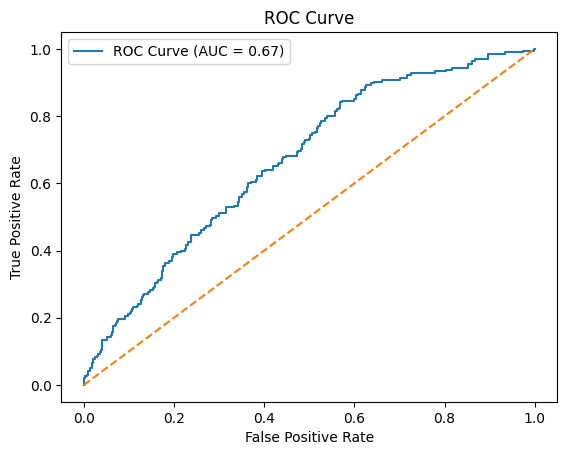

In [18]:
y_prob = pipeline.predict_proba(x_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [19]:
XGBoostPipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('xgboost',xgb.XGBClassifier(scale_pos_weight=RatioBetweenSpikesAndNonSpikes))
    ])

In [20]:
ParamGrid = {
    'xgboost__max_depth' : [3,4,5],
    'xgboost__n_estimators' : [100,200,300],
    'xgboost__learning_rate' : [0.05,0.1,0.15]
}

Scoring = ['f1','precision','recall','roc_auc_ovr']
grid = GridSearchCV(estimator=XGBoostPipeline,param_grid=ParamGrid,scoring=Scoring,cv=3,refit='recall')
#refit is used to decide the most important scoring metric and cv is used to decide the number of attempts per parameter
grid.fit(x_train,y_train)
print(f'The best configurations are {grid.best_params_}')

The best configurations are {'xgboost__learning_rate': 0.05, 'xgboost__max_depth': 3, 'xgboost__n_estimators': 100}


In [21]:
BestXGBoostPipeline = grid.best_estimator_
BestXGBoostPipeline.fit(x_train,y_train)
y_pred_test = BestXGBoostPipeline.predict(x_test)


XGPrecisionScore = precision_score(y_test,y_pred_test)
print(f'Precision : {round(XGPrecisionScore,2)}')

Precision : 0.32


In [22]:
XGRecallScore = recall_score(y_test,y_pred_test)
print(f'Recall Score : {round(XGRecallScore,2)}')

Recall Score : 0.55


In [23]:
XGF1Score = f1_score(y_test,y_pred_test)
print(f'F1 Score : {round(XGF1Score,2)}')

F1 Score : 0.41


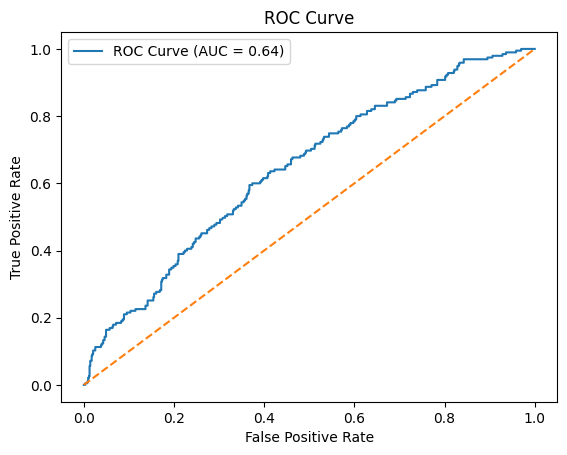

In [24]:
XGYProb = BestXGBoostPipeline.predict_proba(x_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, XGYProb)

roc_auc = roc_auc_score(y_test, XGYProb)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [25]:

# 1. Turn the region integers back into names (SubstituteNames is from your notebook)
IntToRegion = {number: name for name, number in SubstituteNames.items()}

# 2. Build one table: region, the model's predicted risk, and what really happened
RegionResults = pd.DataFrame({
    'Region': x_test['Region'].map(IntToRegion),
    'PredictedRisk': XGYProb,
    'ActualSpike': y_test.astype(float),
})

# 3. Average by region
RegionSummary = RegionResults.groupby('Region').agg(
    Rows=('PredictedRisk', 'size'),
    MeanPredictedRisk=('PredictedRisk', 'mean'),
    ActualSpikeRate=('ActualSpike', 'mean'),
).sort_values('MeanPredictedRisk', ascending=False).round(2)

print(RegionSummary)

                                                   Rows  MeanPredictedRisk  \
Region                                                                       
Latin America & Caribbean                           130               0.55   
Sub-Saharan Africa                                  167               0.52   
Europe & Central Asia                               345               0.43   
East Asia & Pacific                                  94               0.30   
South Asia                                           21               0.30   
Middle East, North Africa, Afghanistan & Pakistan    51               0.27   
North America                                        16               0.14   

                                                   ActualSpikeRate  
Region                                                              
Latin America & Caribbean                                     0.32  
Sub-Saharan Africa                                            0.24  
Europe & Central Asia

This is there to act as a divider between the model evaluation and the actual predictions

In [26]:
X_To_Save = EmptyGiniSpikeValuesDataFrame.copy()
X_To_Pred = EmptyGiniSpikeValuesDataFrame[ColumnsToKeep]
X_To_Pred['Region'] = X_To_Pred['Region'].map(SubstituteNames) 

In [27]:
X_To_Save['RiskScore'] = BestXGBoostPipeline.predict_proba(X_To_Pred)[:, 1]
RiskCSVColumns = ['countryiso3code','date','RiskScore','Region'] #now have region added on to the end
X_To_Save = X_To_Save[RiskCSVColumns]

In [28]:
X_To_Save = pd.merge(X_To_Save,IsoToCountryDataFrame,
                                            how='left',on='countryiso3code')

In [29]:
EmptyGiniSpikeValuesDataFrame = pd.merge(EmptyGiniSpikeValuesDataFrame,IsoToCountryDataFrame,
                                            how='left',on='countryiso3code')

In [31]:
joblib.dump(BestXGBoostPipeline,"XGBoostPipeline.pkl") #this takes the trained model and turns into a pkl file
x_test.to_csv(parent_dir / "XandYDataframes/X_test_Dataframe.csv")
y_test.to_csv(parent_dir / "XandYDataframes/Y_test_Dataframe.csv")
x_train.to_csv(parent_dir / "XandYDataframes/X_train_Dataframe.csv")
y_train.to_csv(parent_dir / "XandYDataframes/Y_train_Dataframe.csv")
X_To_Pred.to_csv(parent_dir / "XandYDataframes/X_Predict_Dataframe.csv") #this is 
X_To_Save.to_csv(parent_dir / 'dashboard/assets/RiskCSVScores.csv')
EmptyGiniSpikeValuesDataFrame.to_csv(parent_dir / 'dashboard/assets/EmptyGiniSpikeValuesDataframe.csv')